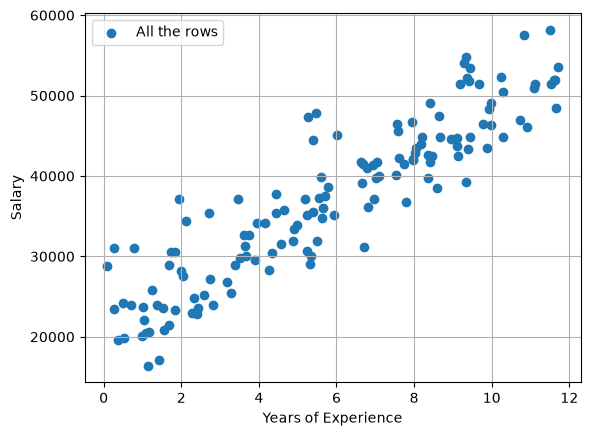

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=42)
years = rng.uniform(0, 12, size=140).round(2)
salary = 22_000 + 2_600 * years + rng.normal(0, 4_000, size=140)
salaries = pd.DataFrame({'YearsExperience': years, 'Salary': salary.round(-2)})

def plot_regression(X_train, y_train, X_test=None, y_test=None, model=None, label='Training rows'):
    plt.scatter(X_train, y_train, color='tab:blue', label=label)
    if X_test is not None:
        plt.scatter(X_test, y_test, color='tab:orange', label='Test rows')
    if model is not None:
        grid = pd.DataFrame({'YearsExperience': np.linspace(X_train.min(), X_train.max(), num=500).ravel()})
        plt.plot(grid, model.predict(grid), color='tab:red', label='Model')
    plt.xlabel('Years of Experience')
    plt.ylabel('Salary')
    plt.legend()
    plt.grid(True)
    plt.show()

X = salaries[['YearsExperience']]
y = salaries['Salary']
plot_regression(X, y, label='All the rows')

The lines after this show how the model works with train data and the approach to the test data

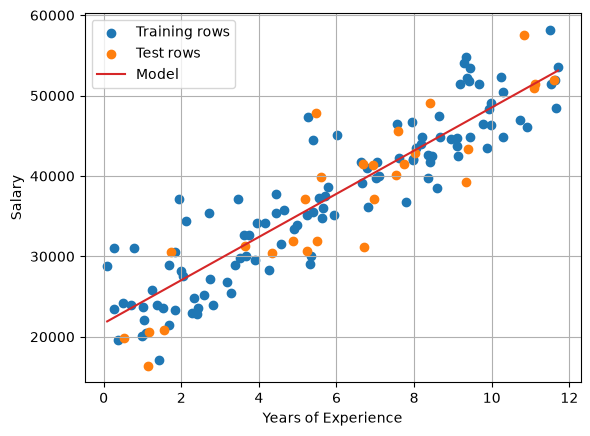

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

linear_model = LinearRegression().fit(X_train, y_train)
plot_regression(X_train, y_train, X_test, y_test, linear_model)

Now we want to see the training MAE and the test MAE

In [19]:
from sklearn.metrics import mean_absolute_error

def train_and_test_error(model):
    return pd.Series({
            'training MAE': mean_absolute_error(y_train, model.predict(X_train)),
            'test MAE': mean_absolute_error(y_test, model.predict(X_test))
        }).round()

train_and_test_error(linear_model)

training MAE    3147.0
test MAE        3647.0
dtype: float64

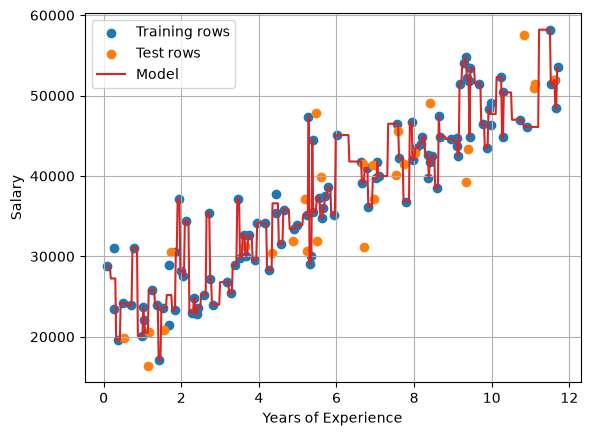

In [20]:
from sklearn.tree import DecisionTreeRegressor

unlimited_tree = DecisionTreeRegressor(random_state=42).fit(X_train, y_train)
plot_regression(X_train, y_train, X_test, y_test, unlimited_tree)

 Now we can see that there is almost no error with the train data but with the test data is even worst than with the linear model version

In [21]:
train_and_test_error(unlimited_tree)

training MAE     190.0
test MAE        4675.0
dtype: float64

## How tree depth affects the error

`max_depth` limits how many splits the tree can make before it gives a prediction. A shallow tree can only learn a rough shape of the data. A deep tree can keep splitting until it almost memorises every training row.

Below we train one tree for each depth from 1 to 10 and compare its training MAE with its test MAE.

In [26]:
depths = range(1,11)
errors_by_depth = pd.DataFrame(
        { depth: train_and_test_error(DecisionTreeRegressor(max_depth=depth, random_state=42).fit(X_train, y_train)) for depth in depths }
        ).T.rename_axis('max_depth')
errors_by_depth

,training MAE,test MAE
max_depth,,
1,4573.0,5719.0
2,3179.0,4277.0
3,2693.0,4453.0
4,2184.0,4402.0
5,1706.0,4471.0
6,1178.0,4550.0
7,875.0,4579.0
8,618.0,4744.0
9,426.0,4668.0


### What the table shows

- **The training MAE keeps falling** as the tree gets deeper, from 4573 at depth 1 to 252 at depth 10. Each extra level lets the tree fit the training rows more closely.
- **The test MAE doesn't follow it.** It's lowest at depth 2 (4277), then slowly gets worse, up to 4777 at depth 10.
- **The gap between the two keeps growing.** That gap is overfitting: after depth 2 the tree is learning the noise in the training rows instead of the real pattern, and that doesn't help it predict rows it hasn't seen.
- **Even the best tree loses to the linear model** (4277 vs 3647 test MAE). The data was generated as a straight line plus noise, so a straight line is the right shape for it, and a tree's step-shaped predictions can't match it.

> Note: here we chose the best depth by looking at the test MAE. In a real project, you'd choose it with a separate validation set (or cross-validation) and keep the test set for one final check. Otherwise the test MAE stops being an honest estimate of how the model does on new data.

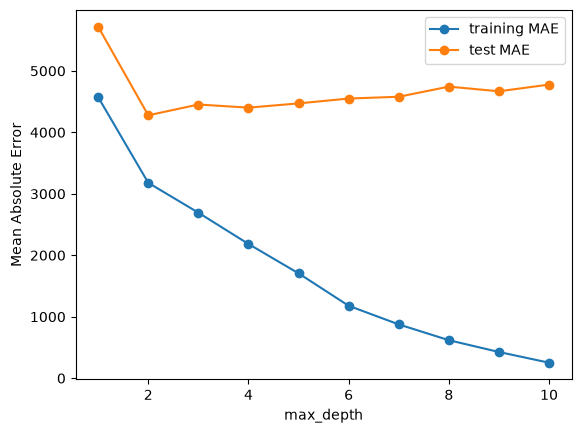

In [29]:
errors_by_depth.plot(marker='o')
plt.ylabel('Mean Absolute Error')
plt.show()

With that image we see thaht the best depth to train our tree is the second, because is the lowest value of test MAE we have.
If we use more depths than that we are overfitting the model
And if we use less depths than that, we are underfitting the model

In [31]:
best_depth = errors_by_depth['test MAE'].idxmin()
best_depth

2

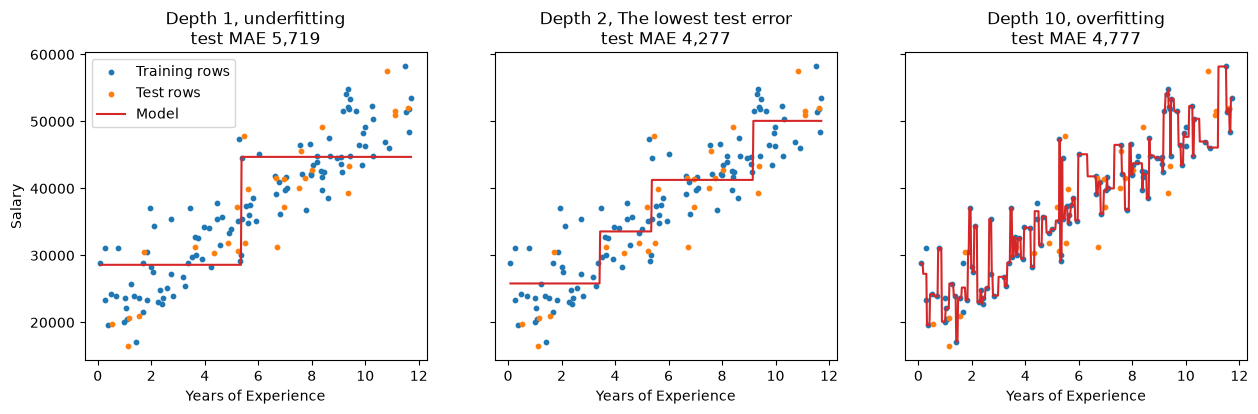

In [33]:
grid = pd.DataFrame({'YearsExperience': np.linspace(X_train.min(), X_train.max(), num=500).ravel()})
shown_depths = { 1: 'underfitting', best_depth: 'The lowest test error', 10: 'overfitting'}
figure, axes = plt.subplots(1,3, figsize=(15, 4), sharey=True)
for axis, (depth, description) in zip(axes, shown_depths.items()):
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42).fit(X_train, y_train)
    axis.scatter(X_train, y_train, color='tab:blue', s=10, label='Training rows')
    axis.scatter(X_test, y_test, color='tab:orange', s=10, label='Test rows')
    axis.plot(grid, tree.predict(grid), color='tab:red', label='Model')
    axis.set_title(f"Depth {depth}, {description}\ntest MAE {errors_by_depth.loc[depth, 'test MAE']:,.0f}")
    axis.set_xlabel("Years of Experience")
axes[0].set_ylabel('Salary')
axes[0].legend()
plt.show()